<a href="https://colab.research.google.com/github/code10-td/Web-Site---Fytverse/blob/main/project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
# CELL 1: CHECK GPU
# ============================================

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available.")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [2]:
# ============================================
# CELL 2: INSTALL LIBRARIES
# ============================================

!pip install -q timm scikit-learn seaborn

In [3]:
# ============================================
# CELL 3: IMPORT LIBRARIES
# ============================================

import os
import random
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import timm
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
# ============================================
# CELL 4: RANDOM SEED
# ============================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [5]:
# ============================================
# CELL 5: MOUNT GOOGLE DRIVE
# ============================================

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
# ============================================
# CELL 6: DATASET PATH
# ============================================

import os

DATASET_DIR = "/content/drive/MyDrive/split_dataset"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VAL_DIR = os.path.join(DATASET_DIR, "validation")
CALIBRATION_DIR = os.path.join(DATASET_DIR, "calibration")
TEST_DIR = os.path.join(DATASET_DIR, "test")

print("Main Dataset:", DATASET_DIR)
print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Calibration:", CALIBRATION_DIR)
print("Test:", TEST_DIR)

print("\nPath Exists:")
print("Train:", os.path.exists(TRAIN_DIR))
print("Validation:", os.path.exists(VAL_DIR))
print("Calibration:", os.path.exists(CALIBRATION_DIR))
print("Test:", os.path.exists(TEST_DIR))

Main Dataset: /content/drive/MyDrive/split_dataset
Train: /content/drive/MyDrive/split_dataset/train
Validation: /content/drive/MyDrive/split_dataset/validation
Calibration: /content/drive/MyDrive/split_dataset/calibration
Test: /content/drive/MyDrive/split_dataset/test

Path Exists:
Train: True
Validation: True
Calibration: True
Test: True


In [12]:
# ============================================
# CHECK 22 CLASSES
# ============================================

train_classes = sorted([
    folder for folder in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, folder))
])

val_classes = sorted([
    folder for folder in os.listdir(VAL_DIR)
    if os.path.isdir(os.path.join(VAL_DIR, folder))
])

calibration_classes = sorted([
    folder for folder in os.listdir(CALIBRATION_DIR)
    if os.path.isdir(os.path.join(CALIBRATION_DIR, folder))
])

test_classes = sorted([
    folder for folder in os.listdir(TEST_DIR)
    if os.path.isdir(os.path.join(TEST_DIR, folder))
])

print("Train classes:", len(train_classes))
print("Validation classes:", len(val_classes))
print("Calibration classes:", len(calibration_classes))
print("Test classes:", len(test_classes))

print("\nClass names:")
for i, cls in enumerate(train_classes):
    print(i, ":", cls)

Train classes: 22
Validation classes: 22
Calibration classes: 22
Test classes: 22

Class names:
0 : Acne
1 : Actinic_Keratosis
2 : Benign_tumors
3 : Bullous
4 : Candidiasis
5 : DrugEruption
6 : Eczema
7 : Infestations_Bites
8 : Lichen
9 : Lupus
10 : Moles
11 : Psoriasis
12 : Rosacea
13 : Seborrh_Keratoses
14 : SkinCancer
15 : Sun_Sunlight_Damage
16 : Tinea
17 : Unknown_Normal
18 : Vascular_Tumors
19 : Vasculitis
20 : Vitiligo
21 : Warts


In [14]:
# ============================================
# COUNT IMAGES PER CLASS
# ============================================

import os

IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def count_images_per_class(folder_path):
    counts = {}

    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)

        if os.path.isdir(class_path):
            count = sum(
                1 for file in os.listdir(class_path)
                if file.lower().endswith(IMAGE_EXTENSIONS)
            )
            counts[class_name] = count

    return counts


# Count images
train_counts = count_images_per_class(TRAIN_DIR)
val_counts = count_images_per_class(VAL_DIR)
calibration_counts = count_images_per_class(CALIBRATION_DIR)
test_counts = count_images_per_class(TEST_DIR)


# Print results
print("=" * 80)
print("IMAGE COUNT PER CLASS")
print("=" * 80)

all_classes = sorted(
    set(train_counts) |
    set(val_counts) |
    set(calibration_counts) |
    set(test_counts)
)

print(f"{'Class':<35} {'Train':>8} {'Val':>8} {'Calibration':>14} {'Test':>8}")
print("-" * 80)

for cls in all_classes:
    print(
        f"{cls:<35} "
        f"{train_counts.get(cls, 0):>8} "
        f"{val_counts.get(cls, 0):>8} "
        f"{calibration_counts.get(cls, 0):>14} "
        f"{test_counts.get(cls, 0):>8}"
    )

print("-" * 80)

print(
    f"{'TOTAL':<35} "
    f"{sum(train_counts.values()):>8} "
    f"{sum(val_counts.values()):>8} "
    f"{sum(calibration_counts.values()):>14} "
    f"{sum(test_counts.values()):>8}"
)

IMAGE COUNT PER CLASS
Class                                  Train      Val    Calibration     Test
--------------------------------------------------------------------------------
Acne                                     220      129            118      107
Actinic_Keratosis                        220      165            159      182
Benign_tumors                            230      238            230      240
Bullous                                  242      118            110       87
Candidiasis                              230       63             59       45
DrugEruption                             239      125            121      126
Eczema                                   239      219            224      230
Infestations_Bites                       230      109            104      118
Lichen                                   230      135            128      118
Lupus                                    230       61             71       71
Moles                                  

In [15]:
# ============================================
# COLLECT IMAGE PATHS AND LABELS
# ============================================

import os

IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')


def collect_image_paths_and_labels(folder_path):
    image_paths = []
    labels = []

    # Get class names
    class_names = sorted([
        folder for folder in os.listdir(folder_path)
        if os.path.isdir(os.path.join(folder_path, folder))
    ])

    # Create label mapping
    class_to_idx = {
        class_name: idx
        for idx, class_name in enumerate(class_names)
    }

    # Collect image paths and labels
    for class_name in class_names:

        class_path = os.path.join(folder_path, class_name)
        label = class_to_idx[class_name]

        for filename in os.listdir(class_path):

            if filename.lower().endswith(IMAGE_EXTENSIONS):

                image_path = os.path.join(class_path, filename)

                image_paths.append(image_path)
                labels.append(label)

    return image_paths, labels, class_names


# ============================================
# COLLECT FOR ALL DATASETS
# ============================================

train_paths, train_labels, class_names = \
    collect_image_paths_and_labels(TRAIN_DIR)

val_paths, val_labels, _ = \
    collect_image_paths_and_labels(VAL_DIR)

calibration_paths, calibration_labels, _ = \
    collect_image_paths_and_labels(CALIBRATION_DIR)

test_paths, test_labels, _ = \
    collect_image_paths_and_labels(TEST_DIR)


# ============================================
# INFORMATION
# ============================================

print("Number of classes:", len(class_names))

print("Train images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Calibration images:", len(calibration_paths))
print("Test images:", len(test_paths))

print("\nClass names:")
for idx, class_name in enumerate(class_names):
    print(idx, "->", class_name)

Number of classes: 22
Train images: 5267
Validation images: 2995
Calibration images: 2921
Test images: 2960

Class names:
0 -> Acne
1 -> Actinic_Keratosis
2 -> Benign_tumors
3 -> Bullous
4 -> Candidiasis
5 -> DrugEruption
6 -> Eczema
7 -> Infestations_Bites
8 -> Lichen
9 -> Lupus
10 -> Moles
11 -> Psoriasis
12 -> Rosacea
13 -> Seborrh_Keratoses
14 -> SkinCancer
15 -> Sun_Sunlight_Damage
16 -> Tinea
17 -> Unknown_Normal
18 -> Vascular_Tumors
19 -> Vasculitis
20 -> Vitiligo
21 -> Warts


In [16]:
# ============================================
# CHECK FIRST 10 IMAGE PATHS AND LABELS
# ============================================

for i in range(10):
    print(
        f"Image: {train_paths[i]}"
    )
    print(
        f"Label: {train_labels[i]} -> {class_names[train_labels[i]]}"
    )
    print("-" * 80)

Image: /content/drive/MyDrive/split_dataset/train/Acne/157__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_test_1.jpeg
Label: 0 -> Acne
--------------------------------------------------------------------------------
Image: /content/drive/MyDrive/split_dataset/train/Acne/161__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd.jpeg
Label: 0 -> Acne
--------------------------------------------------------------------------------
Image: /content/drive/MyDrive/split_dataset/train/Acne/171__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDFd_test_1.jpeg
Label: 0 -> Acne
--------------------------------------------------------------------------------
Image: /content/drive/MyDrive/split_dataset/train/Acne/183__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDE4XQ_test_1.jpeg
Label: 0 -> Acne
--------------------------------------------------------------------------------
Image: /content/drive/MyDrive/split_dataset/train/Acne/183__ProtectWyJQcm90ZWN0Il0_FocusFillWzI5NCwyMjIsIngiLDE4X

In [17]:
# ============================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================

print("=" * 60)
print("DATASET SPLIT INFORMATION")
print("=" * 60)

# Train
print("\nTRAIN SET")
print("Images:", len(train_paths))
print("Labels:", len(train_labels))

# Validation
print("\nVALIDATION SET")
print("Images:", len(val_paths))
print("Labels:", len(val_labels))

# Calibration
print("\nCALIBRATION SET")
print("Images:", len(calibration_paths))
print("Labels:", len(calibration_labels))

# Test
print("\nTEST SET")
print("Images:", len(test_paths))
print("Labels:", len(test_labels))


# ============================================
# CHECK LABEL CONSISTENCY
# ============================================

print("\n" + "=" * 60)
print("CHECKING CLASS CONSISTENCY")
print("=" * 60)

_, _, val_class_names = collect_image_paths_and_labels(VAL_DIR)
_, _, calibration_class_names = collect_image_paths_and_labels(CALIBRATION_DIR)
_, _, test_class_names = collect_image_paths_and_labels(TEST_DIR)

print("Train classes:", len(class_names))
print("Validation classes:", len(val_class_names))
print("Calibration classes:", len(calibration_class_names))
print("Test classes:", len(test_class_names))

if (
    class_names == val_class_names ==
    calibration_class_names ==
    test_class_names
):
    print("\n✓ All datasets have the same 22 classes.")
else:
    print("\n⚠ Class mismatch detected!")

DATASET SPLIT INFORMATION

TRAIN SET
Images: 5267
Labels: 5267

VALIDATION SET
Images: 2995
Labels: 2995

CALIBRATION SET
Images: 2921
Labels: 2921

TEST SET
Images: 2960
Labels: 2960

CHECKING CLASS CONSISTENCY
Train classes: 22
Validation classes: 22
Calibration classes: 22
Test classes: 22

✓ All datasets have the same 22 classes.


In [18]:
# ============================================
# CREATE CUSTOM PYTORCH DATASET
# ============================================

import torch
from torch.utils.data import Dataset
from PIL import Image


class SkinDiseaseDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        # Get image path
        image_path = self.image_paths[index]

        # Get label
        label = self.labels[index]

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply transformation
        if self.transform:
            image = self.transform(image)

        # Convert label to tensor
        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [19]:
# ============================================
# CREATE DATASET OBJECTS
# ============================================

train_dataset = SkinDiseaseDataset(
    train_paths,
    train_labels
)

val_dataset = SkinDiseaseDataset(
    val_paths,
    val_labels
)

calibration_dataset = SkinDiseaseDataset(
    calibration_paths,
    calibration_labels
)

test_dataset = SkinDiseaseDataset(
    test_paths,
    test_labels
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Calibration dataset:", len(calibration_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 5267
Validation dataset: 2995
Calibration dataset: 2921
Test dataset: 2960


In [20]:
# ============================================
# TEST ONE IMAGE
# ============================================

image, label = train_dataset[0]

print("Image shape:", image.size)
print("Label:", label.item())
print("Class:", class_names[label.item()])

Image shape: (294, 222)
Label: 0
Class: Acne


In [21]:
# ============================================
# IMAGE PREPROCESSING
# ============================================

from torchvision import transforms

# Image size for all models
IMAGE_SIZE = 224

# ImageNet mean and standard deviation
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ============================================
# TRAIN TRANSFORM
# ============================================

train_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    # Data augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================
# VALIDATION TRANSFORM
# ============================================

val_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================
# CALIBRATION TRANSFORM
# ============================================

calibration_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================
# TEST TRANSFORM
# ============================================

test_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


print("Image preprocessing completed.")
print("Image size:", IMAGE_SIZE)

Image preprocessing completed.
Image size: 224


In [22]:
# ============================================
# APPLY TRANSFORMS TO DATASETS
# ============================================

train_dataset = SkinDiseaseDataset(
    train_paths,
    train_labels,
    transform=train_transform
)

val_dataset = SkinDiseaseDataset(
    val_paths,
    val_labels,
    transform=val_transform
)

calibration_dataset = SkinDiseaseDataset(
    calibration_paths,
    calibration_labels,
    transform=calibration_transform
)

test_dataset = SkinDiseaseDataset(
    test_paths,
    test_labels,
    transform=test_transform
)

print("Transforms applied successfully.")

Transforms applied successfully.


In [23]:
# ============================================
# CHECK PREPROCESSED IMAGE
# ============================================

image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Label:", label.item())
print("Class:", class_names[label.item()])
print("Data type:", image.dtype)

Image tensor shape: torch.Size([3, 224, 224])
Label: 0
Class: Acne
Data type: torch.float32


In [24]:
# ============================================
# CREATE DATASET OBJECTS
# ============================================

train_dataset = SkinDiseaseDataset(
    image_paths=train_paths,
    labels=train_labels,
    transform=train_transform
)

val_dataset = SkinDiseaseDataset(
    image_paths=val_paths,
    labels=val_labels,
    transform=val_transform
)

calibration_dataset = SkinDiseaseDataset(
    image_paths=calibration_paths,
    labels=calibration_labels,
    transform=calibration_transform
)

test_dataset = SkinDiseaseDataset(
    image_paths=test_paths,
    labels=test_labels,
    transform=test_transform
)


# ============================================
# CHECK DATASET SIZES
# ============================================

print("Train Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Calibration Dataset:", len(calibration_dataset))
print("Test Dataset:", len(test_dataset))

Train Dataset: 5267
Validation Dataset: 2995
Calibration Dataset: 2921
Test Dataset: 2960


In [25]:
# ============================================
# CHECK SAMPLE
# ============================================

image, label = train_dataset[0]

print("\nSample Information")
print("-------------------------")
print("Image shape:", image.shape)
print("Label:", label.item())
print("Class:", class_names[label.item()])
print("Data type:", image.dtype)


Sample Information
-------------------------
Image shape: torch.Size([3, 224, 224])
Label: 0
Class: Acne
Data type: torch.float32


In [26]:
# ============================================
# CREATE DATALOADERS
# ============================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

calibration_loader = DataLoader(
    calibration_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================
# CHECK DATALOADERS
# ============================================

print("DataLoaders created successfully!")
print("-----------------------------------")

print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Calibration batches:", len(calibration_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
-----------------------------------
Batch size: 32
Train batches: 165
Validation batches: 94
Calibration batches: 92
Test batches: 93


In [27]:
# ============================================
# CHECK ONE TRAINING BATCH
# ============================================

images, labels = next(iter(train_loader))

print("\nOne Batch Information")
print("-----------------------------------")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])


One Batch Information
-----------------------------------
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
First 10 labels: tensor([10,  2, 12,  7, 13,  1, 16, 20, 15,  4])


In [28]:
!pip install -q timm

In [29]:
# ============================================
# CREATE EFFICIENTNET-B0
# ============================================

import torch
import torch.nn as nn
import timm

# Number of classes
NUM_CLASSES = 22

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================
# CREATE MODEL
# ============================================

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=NUM_CLASSES
)

# Move model to GPU/CPU
model = model.to(device)


# ============================================
# MODEL INFORMATION
# ============================================

print("\nModel created successfully!")
print("Model: EfficientNet-B0")
print("Number of classes:", NUM_CLASSES)
print("Device:", device)

Device: cuda


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            


Model created successfully!
Model: EfficientNet-B0
Number of classes: 22
Device: cuda


In [30]:
# ============================================
# CHECK FINAL CLASSIFIER
# ============================================

print(model.classifier)

Linear(in_features=1280, out_features=22, bias=True)


In [31]:
# ============================================
# LOSS FUNCTION AND OPTIMIZER
# ============================================

import torch
import torch.nn as nn
import torch.optim as optim


# ============================================
# LOSS FUNCTION
# ============================================

criterion = nn.CrossEntropyLoss()


# ============================================
# OPTIMIZER
# ============================================

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# ============================================
# PRINT SETTINGS
# ============================================

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Learning Rate:", 1e-4)
print("Weight Decay:", 1e-4)

Loss Function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Learning Rate: 0.0001
Weight Decay: 0.0001


In [38]:
from tqdm.auto import tqdm
import torch

def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs=10
):
    best_val_accuracy = 0.0

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(num_epochs):

        # =========================
        # TRAINING
        # =========================
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        train_progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Training"
        )

        for images, labels in train_progress:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            current_loss = running_loss / total
            current_accuracy = 100 * correct / total

            train_progress.set_postfix(
                loss=f"{current_loss:.4f}",
                acc=f"{current_accuracy:.2f}%"
            )

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        # =========================
        # VALIDATION
        # =========================
        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        val_progress = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Validation"
        )

        with torch.no_grad():

            for images, labels in val_progress:

                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_running_loss / val_total
        val_accuracy = 100 * val_correct / val_total

        # =========================
        # SAVE HISTORY
        # =========================
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)

        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        # =========================
        # SAVE BEST MODEL
        # =========================
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            torch.save(
                model.state_dict(),
                "best_efficientnet_b0.pth"
            )

            print("✓ Best model saved!")

        # =========================
        # EPOCH RESULT
        # =========================
        print(
            f"\nEpoch [{epoch+1}/{num_epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_accuracy:.2f}% "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Acc: {val_accuracy:.2f}%"
        )

    print("\nTraining completed!")
    print(
        f"Best Validation Accuracy: "
        f"{best_val_accuracy:.2f}%"
    )

    return history

In [39]:
# ============================================
# TRAIN EFFICIENTNET-B0
# ============================================

NUM_EPOCHS = 10

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    num_epochs=NUM_EPOCHS
)

Epoch 1/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 1/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

✓ Best model saved!

Epoch [1/10] | Train Loss: 1.2289 | Train Acc: 64.15% | Val Loss: 2.4900 | Val Acc: 37.36%


Epoch 2/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 2/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

...

✓ Best model saved!

Epoch [9/10] | Train Loss: 0.0825 | Train Acc: 98.16% | Val Loss: 2.6917 | Val Acc: 49.18%


Epoch 10/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e1638d0e0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e1638d0e0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    
if w.is_alive():  File "/usr/lib/

Epoch 10/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

✓ Best model saved!

Epoch [10/10] | Train Loss: 0.0649 | Train Acc: 98.71% | Val Loss: 2.6667 | Val Acc: 49.95%

Training completed!
Best Validation Accuracy: 49.95%


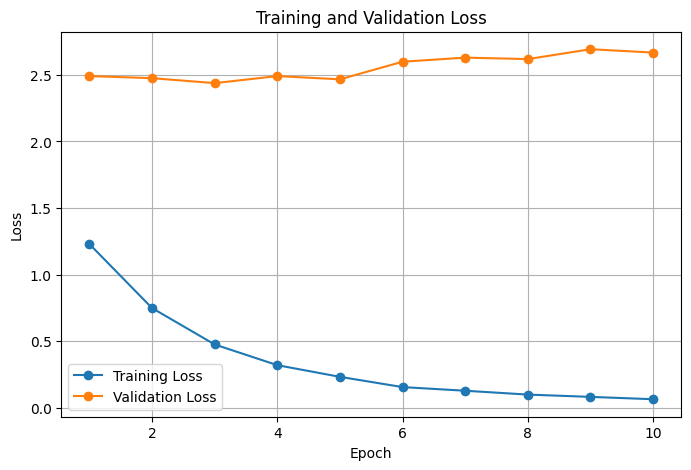

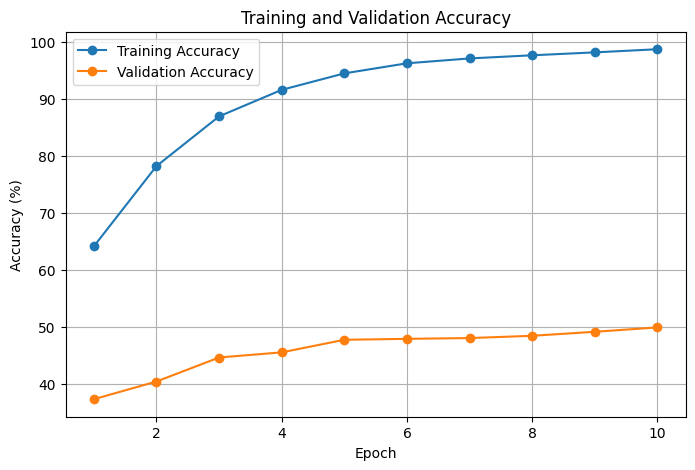

In [40]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# =========================
# Training & Validation Loss
# =========================
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


# =========================
# Training & Validation Accuracy
# =========================
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [42]:
import torch

# Best model checkpoint load
model.load_state_dict(
    torch.load(
        "best_efficientnet_b0.pth",
        map_location=device
    )
)

# Move model to GPU
model = model.to(device)

# Evaluation mode
model.eval()

print("✓ Best EfficientNet-B0 model loaded successfully!")
print("✓ Model is ready for evaluation.")

✓ Best EfficientNet-B0 model loaded successfully!
✓ Model is ready for evaluation.


In [43]:
print("Model device:", next(model.parameters()).device)
print("Model mode:", "Evaluation" if not model.training else "Training")

Model device: cuda:0
Model mode: Evaluation


In [44]:
import torch

# =========================
# Test the Best Model
# =========================

model.eval()

test_correct = 0
test_total = 0
test_running_loss = 0.0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Model prediction
        outputs = model(images)

        # Test loss
        loss = criterion(outputs, labels)

        test_running_loss += loss.item() * images.size(0)

        # Prediction
        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

        # Save predictions and actual labels
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# =========================
# Calculate Test Results
# =========================

test_loss = test_running_loss / test_total
test_accuracy = 100 * test_correct / test_total

print("===================================")
print("       EfficientNet-B0 Test")
print("===================================")

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.2f}%")
print(f"Test Images   : {test_total}")

       EfficientNet-B0 Test
Test Loss     : 2.7804
Test Accuracy : 49.05%
Test Images   : 2960


In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# =========================
# Calculate Metrics
# =========================

accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

# =========================
# Display Results
# =========================

print("======================================")
print(" EfficientNet-B0 Test Performance")
print("======================================")

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")

 EfficientNet-B0 Test Performance
Accuracy  : 49.05%
Precision : 50.93%
Recall    : 49.05%
F1-Score  : 48.37%


In [46]:
from sklearn.metrics import classification_report

# =========================
# Classification Report
# =========================

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("==============================================")
print("      EfficientNet-B0 Classification Report")
print("==============================================")

print(report)

      EfficientNet-B0 Classification Report
                     precision    recall  f1-score   support

               Acne     0.6768    0.6262    0.6505       107
  Actinic_Keratosis     0.7195    0.3242    0.4470       182
      Benign_tumors     0.5532    0.3250    0.4094       240
            Bullous     0.3980    0.4483    0.4216        87
        Candidiasis     0.3107    0.7111    0.4324        45
       DrugEruption     0.3445    0.3254    0.3347       126
             Eczema     0.5267    0.3000    0.3823       230
 Infestations_Bites     0.3790    0.3983    0.3884       118
             Lichen     0.3922    0.3390    0.3636       118
              Lupus     0.3883    0.5634    0.4598        71
              Moles     0.4364    0.5455    0.4848        88
          Psoriasis     0.4430    0.3665    0.4011       191
            Rosacea     0.4369    0.7895    0.5625        57
  Seborrh_Keratoses     0.4685    0.5417    0.5024        96
         SkinCancer     0.4101    0.4591

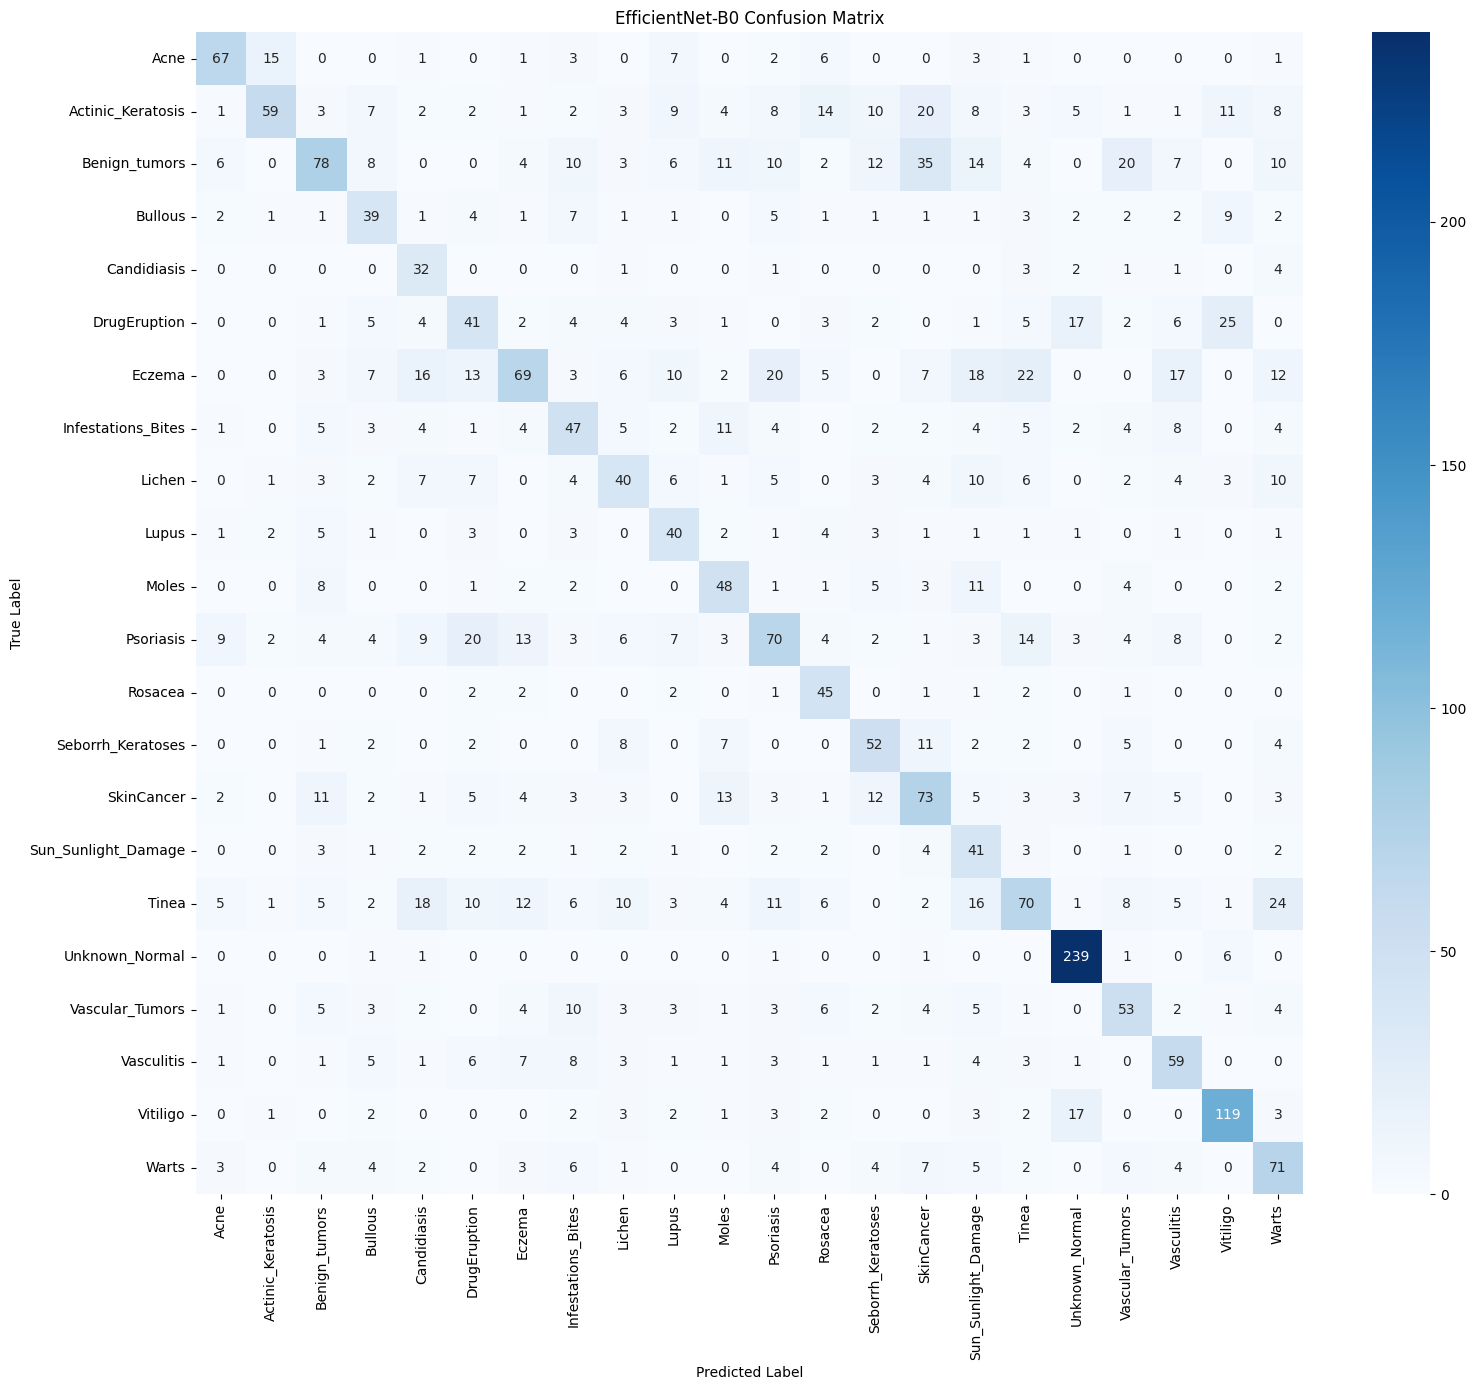

In [47]:
# ============================================
# CELL 26: CONFUSION MATRIX
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

# Plot
plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNet-B0 Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [48]:
# ============================================
# CELL 27: ConvNeXt-Tiny Model
# ============================================

import torch
import torch.nn as nn
import timm

NUM_CLASSES = 22

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create pretrained ConvNeXt-Tiny
convnext_model = timm.create_model(
    "convnext_tiny",
    pretrained=True,
    num_classes=NUM_CLASSES
)

# Move model to GPU
convnext_model = convnext_model.to(device)

print("Model: ConvNeXt-Tiny")
print("Number of classes:", NUM_CLASSES)
print("Device:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: ConvNeXt-Tiny
Number of classes: 22
Device: cuda


In [49]:
# ============================================
# CELL 28: ConvNeXt-Tiny Forward Test
# ============================================

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = convnext_model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 22])
Labels shape: torch.Size([32])


In [50]:
# ============================================
# CELL 29: Loss Function & Optimizer
# ============================================

import torch.optim as optim

convnext_criterion = nn.CrossEntropyLoss()

convnext_optimizer = optim.AdamW(
    convnext_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss Function:", convnext_criterion)
print("Optimizer:", convnext_optimizer)
print("Learning Rate:", 1e-4)
print("Weight Decay:", 1e-4)

Loss Function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Learning Rate: 0.0001
Weight Decay: 0.0001


In [51]:
# ============================================
# CELL 30: Train ConvNeXt-Tiny
# ============================================

from tqdm.auto import tqdm
import torch

def train_convnext(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs=10
):

    best_val_accuracy = 0.0

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(num_epochs):

        # =========================
        # TRAINING
        # =========================

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        train_progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Training"
        )

        for images, labels in train_progress:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # Clear gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            # Loss
            running_loss += (
                loss.item() * images.size(0)
            )

            # Accuracy
            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

            current_loss = running_loss / total

            current_accuracy = (
                100 * correct / total
            )

            train_progress.set_postfix(
                loss=f"{current_loss:.4f}",
                acc=f"{current_accuracy:.2f}%"
            )

        train_loss = running_loss / total

        train_accuracy = (
            100 * correct / total
        )

        # =========================
        # VALIDATION
        # =========================

        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        val_progress = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Validation"
        )

        with torch.no_grad():

            for images, labels in val_progress:

                images = images.to(
                    device,
                    non_blocking=True
                )

                labels = labels.to(
                    device,
                    non_blocking=True
                )

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                val_running_loss += (
                    loss.item() * images.size(0)
                )

                _, predicted = torch.max(
                    outputs,
                    1
                )

                val_total += labels.size(0)

                val_correct += (
                    predicted == labels
                ).sum().item()

        val_loss = (
            val_running_loss / val_total
        )

        val_accuracy = (
            100 * val_correct / val_total
        )

        # =========================
        # SAVE HISTORY
        # =========================

        history["train_loss"].append(
            train_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        # =========================
        # SAVE BEST MODEL
        # =========================

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            torch.save(
                model.state_dict(),
                "best_convnext_tiny.pth"
            )

            print(
                "✓ Best ConvNeXt-Tiny model saved!"
            )

        # =========================
        # EPOCH RESULT
        # =========================

        print(
            f"\nEpoch [{epoch+1}/{num_epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_accuracy:.2f}% "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Acc: {val_accuracy:.2f}%"
        )

    print("\nTraining completed!")

    print(
        f"Best Validation Accuracy: "
        f"{best_val_accuracy:.2f}%"
    )

    return history

In [52]:
# ============================================
# CELL 31: Start ConvNeXt-Tiny Training
# ============================================

NUM_EPOCHS = 10

convnext_history = train_convnext(
    model=convnext_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=convnext_criterion,
    optimizer=convnext_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS
)

Epoch 1/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 1/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

✓ Best ConvNeXt-Tiny model saved!

Epoch [1/10] | Train Loss: 2.0251 | Train Acc: 37.86% | Val Loss: 2.2832 | Val Acc: 39.33%


Epoch 2/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 2/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

...

Epoch 9/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

✓ Best ConvNeXt-Tiny model saved!

Epoch [9/10] | Train Loss: 0.0853 | Train Acc: 97.47% | Val Loss: 2.9981 | Val Acc: 52.29%


Epoch 10/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 10/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]


Epoch [10/10] | Train Loss: 0.0687 | Train Acc: 97.65% | Val Loss: 3.1207 | Val Acc: 50.75%

Training completed!
Best Validation Accuracy: 52.29%


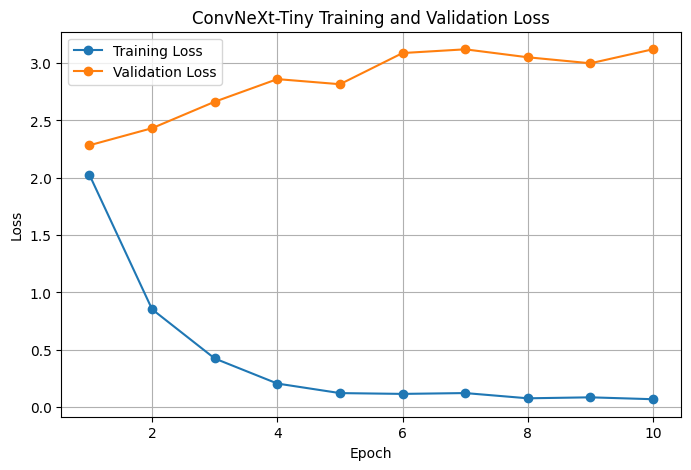

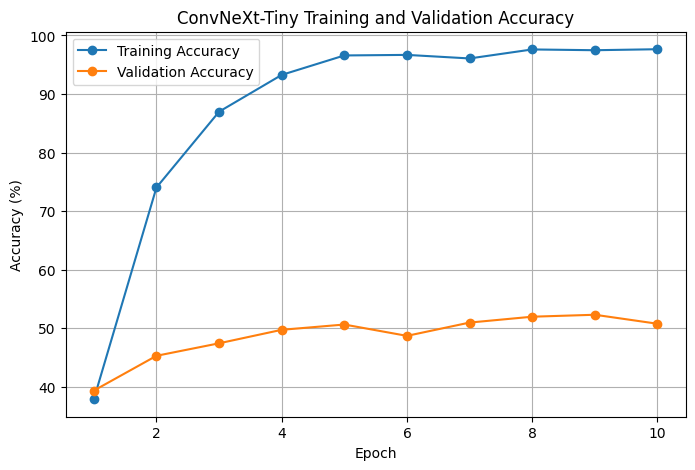

In [53]:
# ============================================
# CELL 32: Plot ConvNeXt-Tiny Training Result
# ============================================

import matplotlib.pyplot as plt

epochs = range(
    1,
    len(convnext_history["train_loss"]) + 1
)

# =========================
# Loss
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    convnext_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    convnext_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ConvNeXt-Tiny Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()


# =========================
# Accuracy
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    convnext_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    convnext_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "ConvNeXt-Tiny Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()

In [54]:
# ============================================
# CELL 33: Load Best ConvNeXt-Tiny Model
# ============================================

convnext_model.load_state_dict(
    torch.load(
        "best_convnext_tiny.pth",
        map_location=device
    )
)

convnext_model = convnext_model.to(device)

convnext_model.eval()

print(
    "✓ Best ConvNeXt-Tiny model loaded successfully!"
)

print(
    "✓ Model is ready for evaluation."
)

✓ Best ConvNeXt-Tiny model loaded successfully!
✓ Model is ready for evaluation.


In [55]:
# ============================================
# CELL 34: Test ConvNeXt-Tiny
# ============================================

convnext_model.eval()

test_correct = 0
test_total = 0
test_running_loss = 0.0

# Store predictions and labels
convnext_predictions = []
convnext_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Prediction
        outputs = convnext_model(images)

        # Loss
        loss = convnext_criterion(
            outputs,
            labels
        )

        test_running_loss += (
            loss.item() * images.size(0)
        )

        # Predicted class
        _, predicted = torch.max(
            outputs,
            1
        )

        test_total += labels.size(0)

        test_correct += (
            predicted == labels
        ).sum().item()

        # Save predictions
        convnext_predictions.extend(
            predicted.cpu().numpy()
        )

        # Save true labels
        convnext_labels.extend(
            labels.cpu().numpy()
        )


# =========================
# Test Results
# =========================

convnext_test_loss = (
    test_running_loss / test_total
)

convnext_test_accuracy = (
    100 * test_correct / test_total
)

print("===================================")
print("      ConvNeXt-Tiny Test")
print("===================================")

print(
    f"Test Loss     : "
    f"{convnext_test_loss:.4f}"
)

print(
    f"Test Accuracy : "
    f"{convnext_test_accuracy:.2f}%"
)

print(
    f"Test Images   : "
    f"{test_total}"
)

      ConvNeXt-Tiny Test
Test Loss     : 2.9404
Test Accuracy : 52.60%
Test Images   : 2960


In [56]:
# ============================================
# CELL 35: ConvNeXt-Tiny Metrics
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    convnext_labels,
    convnext_predictions
)

precision = precision_score(
    convnext_labels,
    convnext_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    convnext_labels,
    convnext_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    convnext_labels,
    convnext_predictions,
    average="weighted",
    zero_division=0
)

print("======================================")
print("     ConvNeXt-Tiny Test Performance")
print("======================================")

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1-Score  : {f1 * 100:.2f}%"
)

     ConvNeXt-Tiny Test Performance
Accuracy  : 52.60%
Precision : 56.29%
Recall    : 52.60%
F1-Score  : 52.55%


In [57]:
# ============================================
# CELL 36: ConvNeXt-Tiny Classification Report
# ============================================

from sklearn.metrics import classification_report

report = classification_report(
    convnext_labels,
    convnext_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("==============================================")
print("     ConvNeXt-Tiny Classification Report")
print("==============================================")

print(report)

     ConvNeXt-Tiny Classification Report
                     precision    recall  f1-score   support

               Acne     0.5652    0.6075    0.5856       107
  Actinic_Keratosis     0.5443    0.4725    0.5059       182
      Benign_tumors     0.7431    0.3375    0.4642       240
            Bullous     0.4118    0.6437    0.5022        87
        Candidiasis     0.2384    0.8000    0.3673        45
       DrugEruption     0.4821    0.4286    0.4538       126
             Eczema     0.4528    0.5000    0.4752       230
 Infestations_Bites     0.4434    0.3983    0.4196       118
             Lichen     0.5063    0.3390    0.4061       118
              Lupus     0.6667    0.4507    0.5378        71
              Moles     0.4348    0.5682    0.4926        88
          Psoriasis     0.4545    0.2880    0.3526       191
            Rosacea     0.4906    0.9123    0.6380        57
  Seborrh_Keratoses     0.4495    0.5104    0.4780        96
         SkinCancer     0.4076    0.5409   

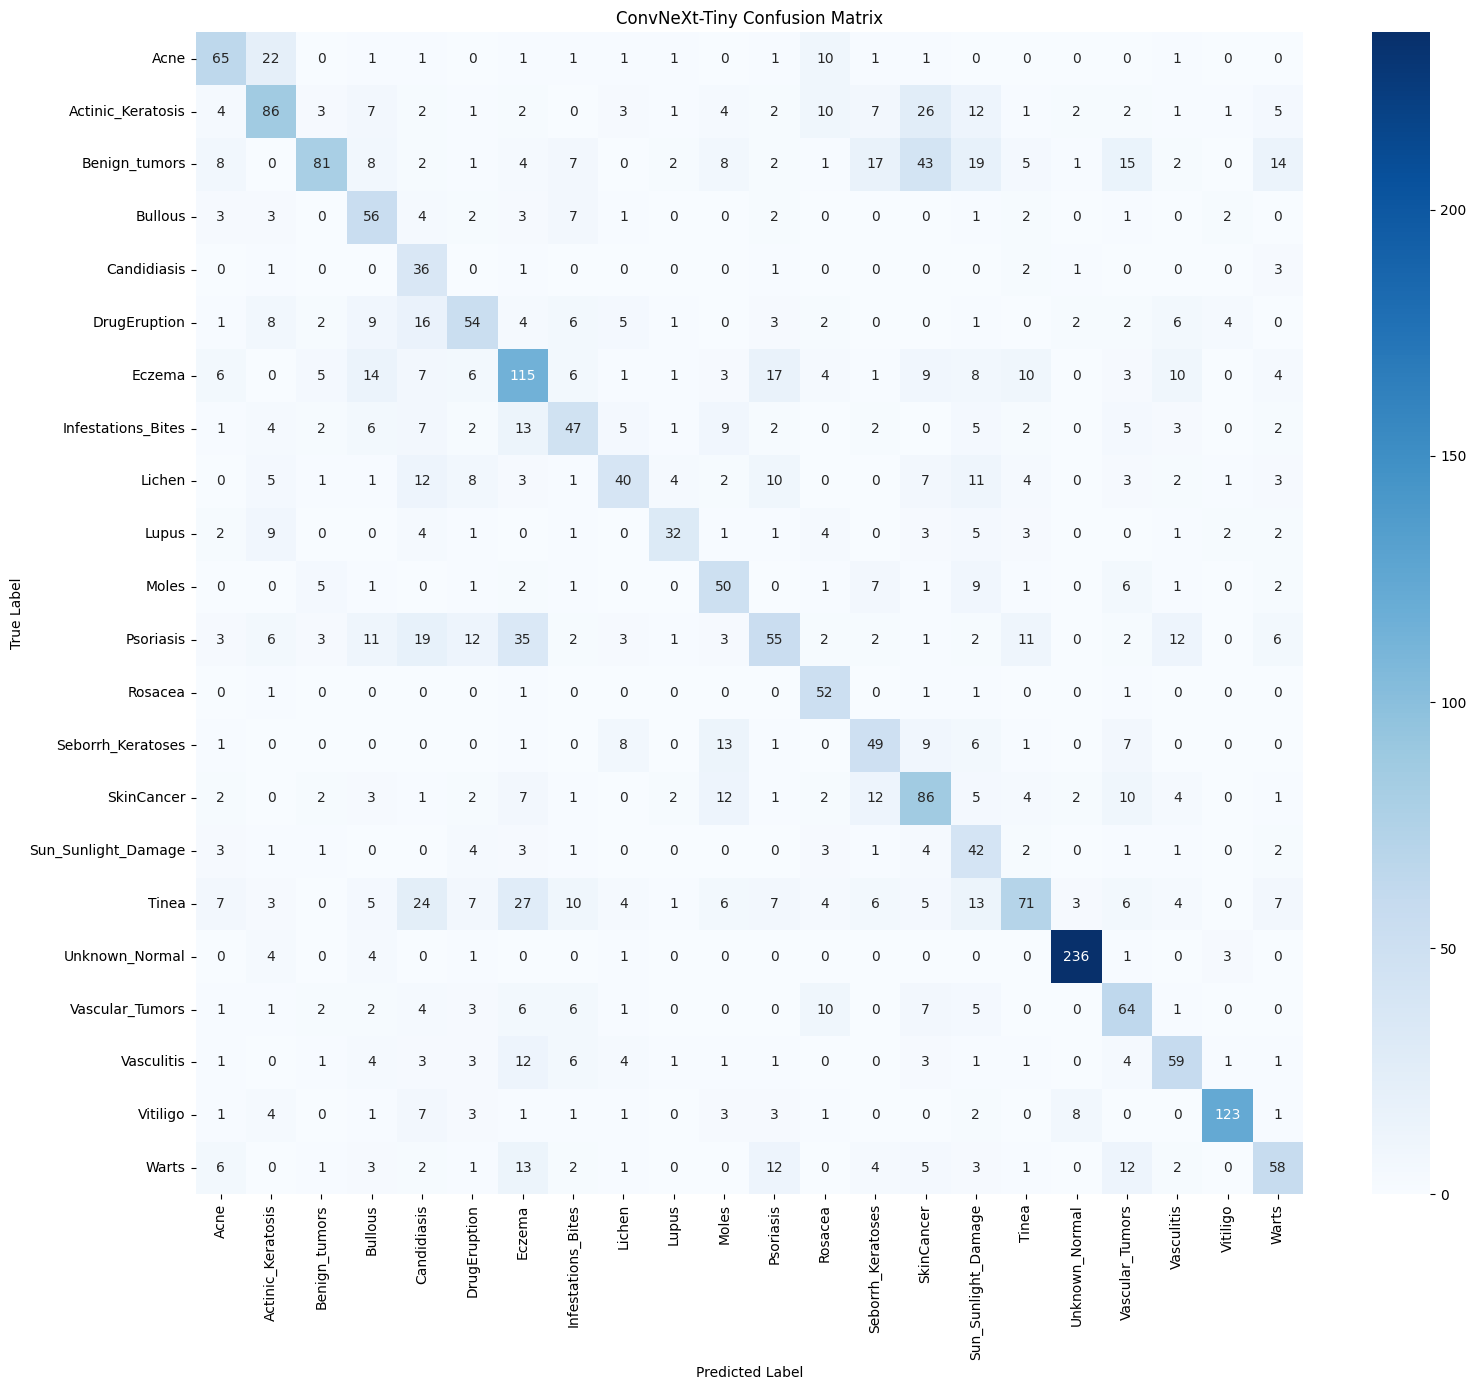

In [58]:
# ============================================
# CELL 37: ConvNeXt-Tiny Confusion Matrix
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_convnext = confusion_matrix(
    convnext_labels,
    convnext_predictions
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_convnext,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "ConvNeXt-Tiny Confusion Matrix"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [59]:
# ============================================
# CELL 38: Swin-Tiny Model
# ============================================

import torch
import torch.nn as nn
import timm

NUM_CLASSES = 22

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create pretrained Swin-Tiny
swin_model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=NUM_CLASSES
)

# Move model to GPU
swin_model = swin_model.to(device)

print("Model: Swin-Tiny")
print("Number of classes:", NUM_CLASSES)
print("Device:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: Swin-Tiny
Number of classes: 22
Device: cuda


In [60]:
# ============================================
# CELL 39: Swin-Tiny Forward Test
# ============================================

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = swin_model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 22])
Labels shape: torch.Size([32])


In [61]:
# ============================================
# CELL 40: Swin-Tiny Loss & Optimizer
# ============================================

import torch.optim as optim

swin_criterion = nn.CrossEntropyLoss()

swin_optimizer = optim.AdamW(
    swin_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss Function:", swin_criterion)
print("Optimizer:", swin_optimizer)
print("Learning Rate:", 1e-4)
print("Weight Decay:", 1e-4)

Loss Function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Learning Rate: 0.0001
Weight Decay: 0.0001


In [62]:
# ============================================
# CELL 41: Train Swin-Tiny
# ============================================

from tqdm.auto import tqdm

def train_swin(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs=10
):

    best_val_accuracy = 0.0

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(num_epochs):

        # =========================
        # TRAINING
        # =========================

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        train_progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Training"
        )

        for images, labels in train_progress:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # Clear gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(
                outputs,
                labels
            )

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            # Loss
            running_loss += (
                loss.item() * images.size(0)
            )

            # Accuracy
            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

            current_loss = (
                running_loss / total
            )

            current_accuracy = (
                100 * correct / total
            )

            train_progress.set_postfix(
                loss=f"{current_loss:.4f}",
                acc=f"{current_accuracy:.2f}%"
            )

        train_loss = (
            running_loss / total
        )

        train_accuracy = (
            100 * correct / total
        )

        # =========================
        # VALIDATION
        # =========================

        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        val_progress = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} - Validation"
        )

        with torch.no_grad():

            for images, labels in val_progress:

                images = images.to(
                    device,
                    non_blocking=True
                )

                labels = labels.to(
                    device,
                    non_blocking=True
                )

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                val_running_loss += (
                    loss.item() * images.size(0)
                )

                _, predicted = torch.max(
                    outputs,
                    1
                )

                val_total += labels.size(0)

                val_correct += (
                    predicted == labels
                ).sum().item()

        val_loss = (
            val_running_loss / val_total
        )

        val_accuracy = (
            100 * val_correct / val_total
        )

        # =========================
        # SAVE HISTORY
        # =========================

        history["train_loss"].append(
            train_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        # =========================
        # SAVE BEST MODEL
        # =========================

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            torch.save(
                model.state_dict(),
                "best_swin_tiny.pth"
            )

            print(
                "✓ Best Swin-Tiny model saved!"
            )

        # =========================
        # EPOCH RESULT
        # =========================

        print(
            f"\nEpoch [{epoch+1}/{num_epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_accuracy:.2f}% "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Acc: {val_accuracy:.2f}%"
        )

    print("\nTraining completed!")

    print(
        f"Best Validation Accuracy: "
        f"{best_val_accuracy:.2f}%"
    )

    return history

In [63]:
# ============================================
# CELL 42: Start Swin-Tiny Training
# ============================================

NUM_EPOCHS = 10

swin_history = train_swin(
    model=swin_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=swin_criterion,
    optimizer=swin_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS
)

Epoch 1/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 1/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

✓ Best Swin-Tiny model saved!

Epoch [1/10] | Train Loss: 1.8152 | Train Acc: 45.38% | Val Loss: 2.1961 | Val Acc: 42.40%


Epoch 2/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 2/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]

...


Epoch [9/10] | Train Loss: 0.1075 | Train Acc: 96.98% | Val Loss: 3.0955 | Val Acc: 50.82%


Epoch 10/10 - Training:   0%|          | 0/165 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e1638d0e0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e1638d0e0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10 - Validation:   0%|          | 0/94 [00:00<?, ?it/s]


Epoch [10/10] | Train Loss: 0.0827 | Train Acc: 97.76% | Val Loss: 2.9731 | Val Acc: 52.45%

Training completed!
Best Validation Accuracy: 52.75%


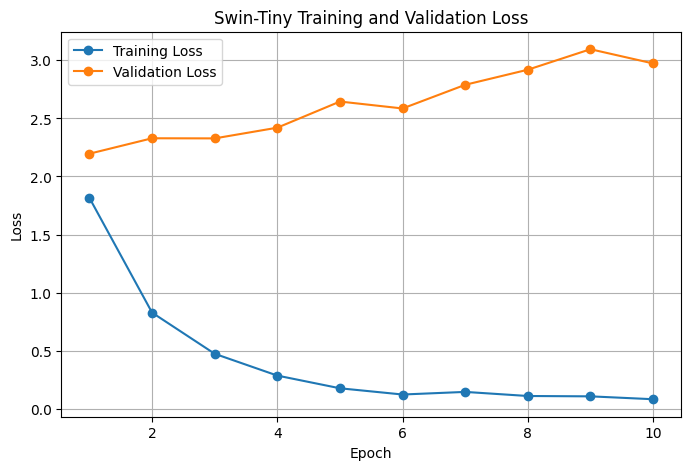

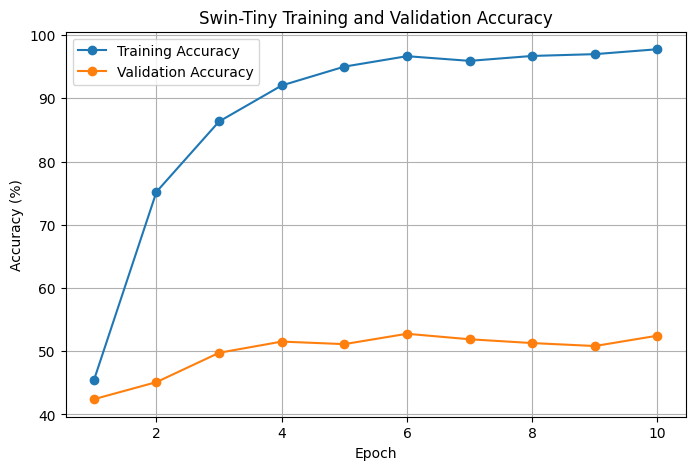

In [64]:
# ============================================
# CELL 43: Plot Swin-Tiny Training Result
# ============================================

import matplotlib.pyplot as plt

epochs = range(
    1,
    len(swin_history["train_loss"]) + 1
)

# =========================
# Loss
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    swin_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    swin_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Swin-Tiny Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()


# =========================
# Accuracy
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    swin_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    swin_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "Swin-Tiny Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()

In [65]:
# ============================================
# CELL 44: Load Best Swin-Tiny Model
# ============================================

swin_model.load_state_dict(
    torch.load(
        "best_swin_tiny.pth",
        map_location=device
    )
)

swin_model = swin_model.to(device)

swin_model.eval()

print(
    "✓ Best Swin-Tiny model loaded successfully!"
)

print(
    "✓ Model is ready for evaluation."
)

✓ Best Swin-Tiny model loaded successfully!
✓ Model is ready for evaluation.


In [66]:
# ============================================
# CELL 45: Test Swin-Tiny
# ============================================

swin_model.eval()

swin_test_correct = 0
swin_test_total = 0
swin_test_running_loss = 0.0

# Store predictions and labels
swin_predictions = []
swin_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Model prediction
        outputs = swin_model(images)

        # Test loss
        loss = swin_criterion(
            outputs,
            labels
        )

        swin_test_running_loss += (
            loss.item() * images.size(0)
        )

        # Predicted class
        _, predicted = torch.max(
            outputs,
            1
        )

        swin_test_total += labels.size(0)

        swin_test_correct += (
            predicted == labels
        ).sum().item()

        # Save predictions
        swin_predictions.extend(
            predicted.cpu().numpy()
        )

        # Save true labels
        swin_labels.extend(
            labels.cpu().numpy()
        )


# =========================
# Test Results
# =========================

swin_test_loss = (
    swin_test_running_loss /
    swin_test_total
)

swin_test_accuracy = (
    100 *
    swin_test_correct /
    swin_test_total
)

print("===================================")
print("          Swin-Tiny Test")
print("===================================")

print(
    f"Test Loss     : "
    f"{swin_test_loss:.4f}"
)

print(
    f"Test Accuracy : "
    f"{swin_test_accuracy:.2f}%"
)

print(
    f"Test Images   : "
    f"{swin_test_total}"
)

          Swin-Tiny Test
Test Loss     : 2.6543
Test Accuracy : 51.45%
Test Images   : 2960


In [67]:
# ============================================
# CELL 46: Swin-Tiny Metrics
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

swin_accuracy = accuracy_score(
    swin_labels,
    swin_predictions
)

swin_precision = precision_score(
    swin_labels,
    swin_predictions,
    average="weighted",
    zero_division=0
)

swin_recall = recall_score(
    swin_labels,
    swin_predictions,
    average="weighted",
    zero_division=0
)

swin_f1 = f1_score(
    swin_labels,
    swin_predictions,
    average="weighted",
    zero_division=0
)

print("======================================")
print("        Swin-Tiny Test Performance")
print("======================================")

print(
    f"Accuracy  : "
    f"{swin_accuracy * 100:.2f}%"
)

print(
    f"Precision : "
    f"{swin_precision * 100:.2f}%"
)

print(
    f"Recall    : "
    f"{swin_recall * 100:.2f}%"
)

print(
    f"F1-Score  : "
    f"{swin_f1 * 100:.2f}%"
)

        Swin-Tiny Test Performance
Accuracy  : 51.45%
Precision : 54.74%
Recall    : 51.45%
F1-Score  : 51.17%


In [68]:
# ============================================
# CELL 47: Swin-Tiny Classification Report
# ============================================

from sklearn.metrics import classification_report

swin_report = classification_report(
    swin_labels,
    swin_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("==============================================")
print("       Swin-Tiny Classification Report")
print("==============================================")

print(swin_report)

       Swin-Tiny Classification Report
                     precision    recall  f1-score   support

               Acne     0.5349    0.6449    0.5847       107
  Actinic_Keratosis     0.6481    0.3846    0.4828       182
      Benign_tumors     0.7273    0.3000    0.4248       240
            Bullous     0.5570    0.5057    0.5301        87
        Candidiasis     0.3505    0.7556    0.4789        45
       DrugEruption     0.3393    0.4524    0.3878       126
             Eczema     0.5926    0.3478    0.4384       230
 Infestations_Bites     0.5270    0.3305    0.4062       118
             Lichen     0.4216    0.3644    0.3909       118
              Lupus     0.4216    0.6056    0.4971        71
              Moles     0.5102    0.5682    0.5376        88
          Psoriasis     0.4565    0.4398    0.4480       191
            Rosacea     0.3824    0.9123    0.5389        57
  Seborrh_Keratoses     0.4862    0.5521    0.5171        96
         SkinCancer     0.3923    0.5157    0

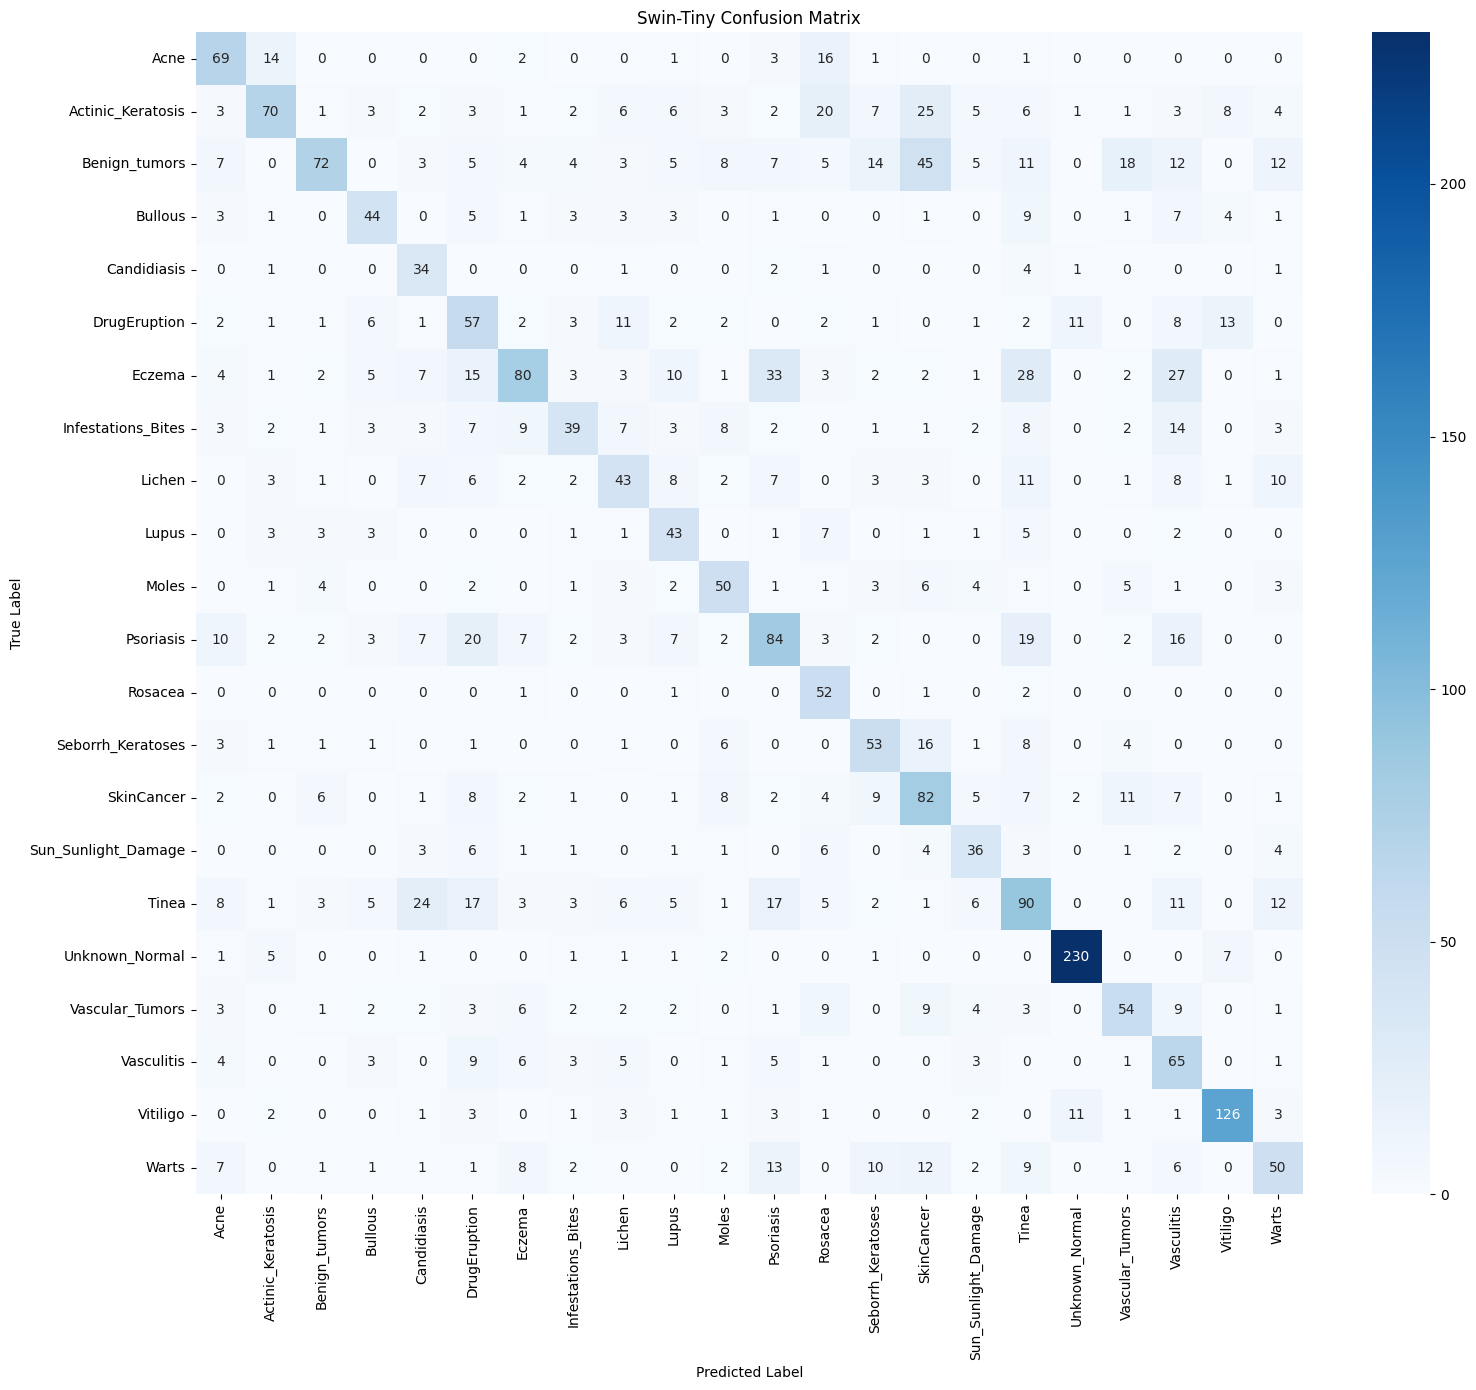

In [69]:
# ============================================
# CELL 48: Swin-Tiny Confusion Matrix
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_swin = confusion_matrix(
    swin_labels,
    swin_predictions
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_swin,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "Swin-Tiny Confusion Matrix"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [70]:
import torch
import torch.nn as nn
import torch.optim as optim
import timm

NUM_CLASSES = 22

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

maxvit_model = timm.create_model(
    "maxvit_tiny_tf_224",
    pretrained=True,
    num_classes=NUM_CLASSES
)

maxvit_model = maxvit_model.to(device)

print("Device:", device)
print("MaxViT-Tiny model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  124MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda
MaxViT-Tiny model loaded successfully!


In [71]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = maxvit_model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 22])
Labels shape: torch.Size([32])


In [72]:
maxvit_criterion = nn.CrossEntropyLoss()

maxvit_optimizer = optim.AdamW(
    maxvit_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Criterion and optimizer ready!")

Criterion and optimizer ready!


In [73]:
from tqdm.auto import tqdm

def train_maxvit(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs=10
):

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = 0.0

    for epoch in range(num_epochs):

        # =========================
        # Training
        # =========================
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        train_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} [Train]"
        )

        for images, labels in train_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            train_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        # =========================
        # Validation
        # =========================
        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            val_bar = tqdm(
                val_loader,
                desc=f"Epoch {epoch+1}/{num_epochs} [Val]"
            )

            for images, labels in val_bar:

                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_running_loss / val_total
        val_accuracy = 100 * val_correct / val_total

        # =========================
        # Save history
        # =========================
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)

        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"\nEpoch [{epoch+1}/{num_epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

        # =========================
        # Save best model
        # =========================
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            torch.save(
                model.state_dict(),
                "best_maxvit_tiny.pth"
            )

            print(
                f"Best MaxViT-Tiny model saved! "
                f"Val Accuracy: {val_accuracy:.2f}%"
            )

    return history

In [74]:
NUM_EPOCHS = 10

maxvit_history = train_maxvit(
    model=maxvit_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=maxvit_criterion,
    optimizer=maxvit_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS
)

Epoch 1/10 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/94 [00:00<?, ?it/s]


Epoch [1/10] Train Loss: 2.2077 | Train Acc: 38.26% | Val Loss: 2.2088 | Val Acc: 37.13%
Best MaxViT-Tiny model saved! Val Accuracy: 37.13%


Epoch 2/10 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 2/10 [Val]:   0%|          | 0/94 [00:00<?, ?it/s]

...

Epoch 9/10 [Val]:   0%|          | 0/94 [00:00<?, ?it/s]


Epoch [9/10] Train Loss: 0.0362 | Train Acc: 99.37% | Val Loss: 2.3255 | Val Acc: 53.32%
Best MaxViT-Tiny model saved! Val Accuracy: 53.32%


Epoch 10/10 [Train]:   0%|          | 0/165 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/94 [00:00<?, ?it/s]


Epoch [10/10] Train Loss: 0.0287 | Train Acc: 99.47% | Val Loss: 2.4164 | Val Acc: 53.19%


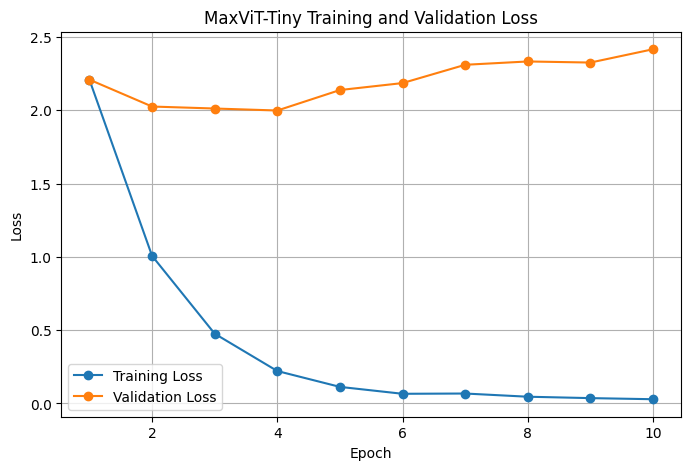

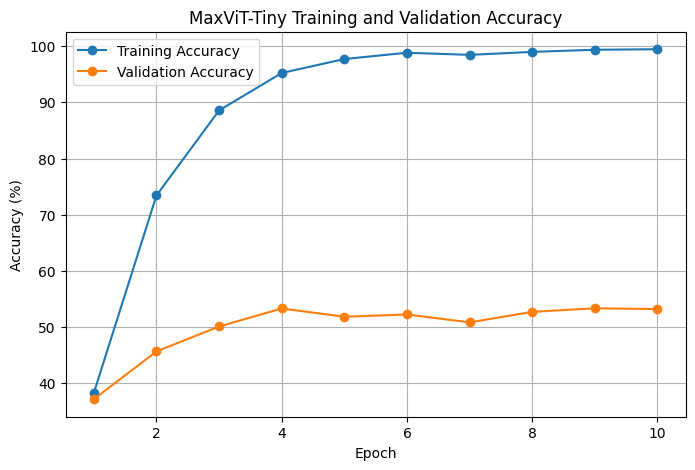

In [75]:
import matplotlib.pyplot as plt

epochs = range(
    1,
    len(maxvit_history["train_loss"]) + 1
)

# =========================
# Loss Curve
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    maxvit_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    maxvit_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MaxViT-Tiny Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


# =========================
# Accuracy Curve
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    maxvit_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    maxvit_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MaxViT-Tiny Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [76]:
maxvit_model.load_state_dict(
    torch.load(
        "best_maxvit_tiny.pth",
        map_location=device
    )
)

maxvit_model = maxvit_model.to(device)

maxvit_model.eval()

print("Best MaxViT-Tiny model loaded successfully!")

Best MaxViT-Tiny model loaded successfully!


In [77]:
maxvit_test_correct = 0
maxvit_test_total = 0
maxvit_test_running_loss = 0.0

maxvit_predictions = []
maxvit_labels = []

maxvit_model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = maxvit_model(images)

        loss = maxvit_criterion(outputs, labels)

        maxvit_test_running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(outputs, 1)

        maxvit_test_total += labels.size(0)

        maxvit_test_correct += (
            predicted == labels
        ).sum().item()

        maxvit_predictions.extend(
            predicted.cpu().numpy()
        )

        maxvit_labels.extend(
            labels.cpu().numpy()
        )


maxvit_test_loss = (
    maxvit_test_running_loss /
    maxvit_test_total
)

maxvit_test_accuracy = (
    100 * maxvit_test_correct /
    maxvit_test_total
)

print(f"MaxViT-Tiny Test Loss: {maxvit_test_loss:.4f}")
print(f"MaxViT-Tiny Test Accuracy: {maxvit_test_accuracy:.2f}%")

MaxViT-Tiny Test Loss: 2.3301
MaxViT-Tiny Test Accuracy: 52.60%


In [78]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

maxvit_accuracy = accuracy_score(
    maxvit_labels,
    maxvit_predictions
)

maxvit_precision = precision_score(
    maxvit_labels,
    maxvit_predictions,
    average="weighted",
    zero_division=0
)

maxvit_recall = recall_score(
    maxvit_labels,
    maxvit_predictions,
    average="weighted",
    zero_division=0
)

maxvit_f1 = f1_score(
    maxvit_labels,
    maxvit_predictions,
    average="weighted",
    zero_division=0
)

print("===== MaxViT-Tiny Metrics =====")

print(f"Accuracy : {maxvit_accuracy:.4f}")
print(f"Precision: {maxvit_precision:.4f}")
print(f"Recall   : {maxvit_recall:.4f}")
print(f"F1 Score : {maxvit_f1:.4f}")

===== MaxViT-Tiny Metrics =====
Accuracy : 0.5260
Precision: 0.5625
Recall   : 0.5260
F1 Score : 0.5246


In [79]:
from sklearn.metrics import classification_report

maxvit_report = classification_report(
    maxvit_labels,
    maxvit_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("===== MaxViT-Tiny Classification Report =====")
print(maxvit_report)

===== MaxViT-Tiny Classification Report =====
                     precision    recall  f1-score   support

               Acne     0.8235    0.6542    0.7292       107
  Actinic_Keratosis     0.9123    0.2857    0.4351       182
      Benign_tumors     0.4567    0.3958    0.4241       240
            Bullous     0.6143    0.4943    0.5478        87
        Candidiasis     0.2555    0.7778    0.3846        45
       DrugEruption     0.3418    0.4286    0.3803       126
             Eczema     0.5187    0.4826    0.5000       230
 Infestations_Bites     0.5949    0.3983    0.4772       118
             Lichen     0.4286    0.4068    0.4174       118
              Lupus     0.5000    0.5634    0.5298        71
              Moles     0.3925    0.4773    0.4308        88
          Psoriasis     0.4121    0.4293    0.4205       191
            Rosacea     0.5632    0.8596    0.6806        57
  Seborrh_Keratoses     0.4488    0.5938    0.5112        96
         SkinCancer     0.4494    0.44

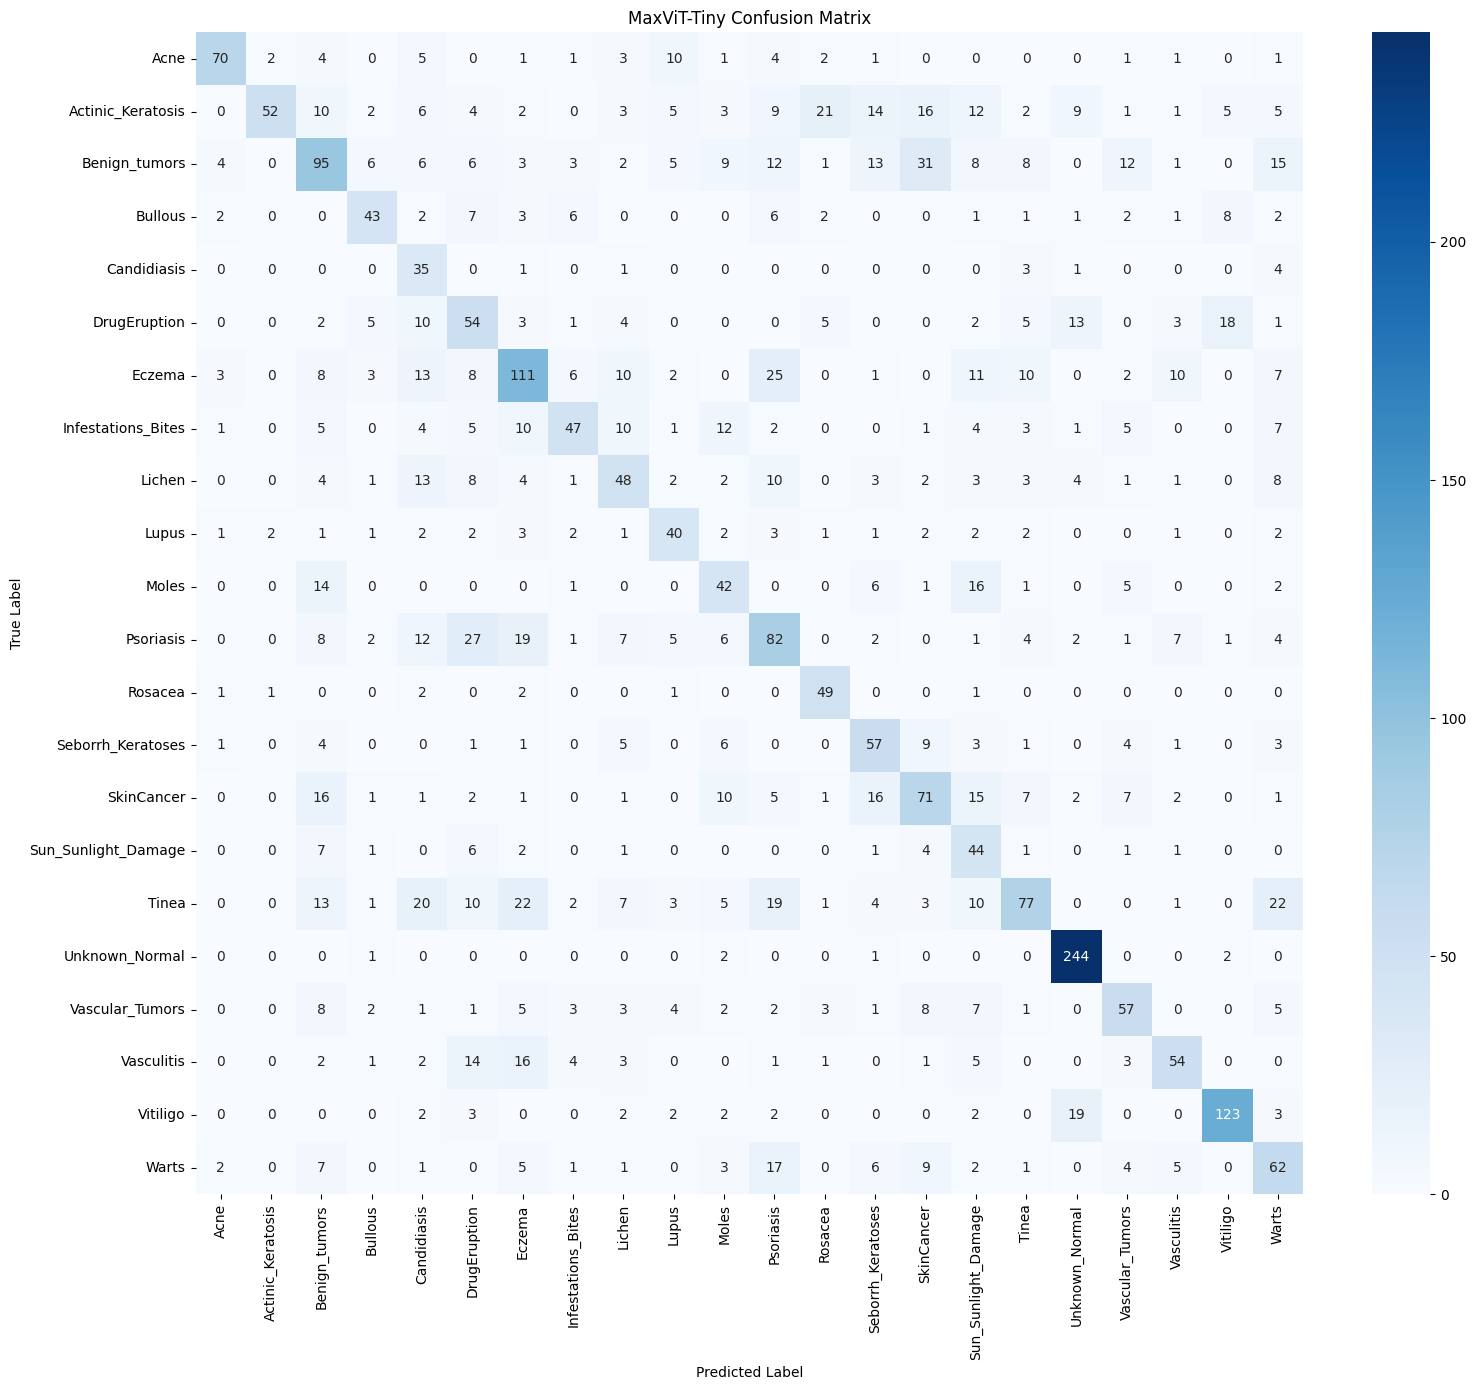

In [80]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_maxvit = confusion_matrix(
    maxvit_labels,
    maxvit_predictions
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_maxvit,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MaxViT-Tiny Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()